# Chargement du dataframe

In [1]:
from pathlib import Path

import pandas as pd
from PIL import Image

# Le notebook est dans notebooks/, donc on remonte d'un cran.
IMAGES_DIR = Path("../data/images")


def build_dataframe(images_dir: Path) -> pd.DataFrame:
    rows: list[dict[str, object]] = []
    for path in sorted(images_dir.glob("*/*.jpg")):
        try:
            # verify() lit l'en-tête sans décoder l'image : rapide, détecte les fichiers corrompus
            with Image.open(path) as img:
                img.verify()
            with Image.open(path) as img:  # il faut rouvrir après verify()
                width, height = img.size
            ok = True
        except Exception:
            width = height = None
            ok = False
        rows.append(
            {
                "path": path,
                "rayon": path.parent.name,  # le dossier parent = l'étiquette
                "code": path.stem,  # code-barres, garde les zéros de tête
                "width": width,
                "height": height,
                "ok": ok,
            }
        )
    return pd.DataFrame(rows)


df = build_dataframe(IMAGES_DIR)
print(f"{len(df)} fichiers, {(~df['ok']).sum()} illisibles")
df.head()

3000 fichiers, 0 illisibles


,path,rayon,code,width,height,ok
0,..\data\images\biscuits\0039047001442.jpg,biscuits,0039047001442,400,300,True
1,..\data\images\biscuits\0061232200293.jpg,biscuits,0061232200293,300,400,True
2,..\data\images\biscuits\0061232202556.jpg,biscuits,0061232202556,400,209,True
3,..\data\images\biscuits\0061232203072.jpg,biscuits,0061232203072,211,400,True
4,..\data\images\biscuits\0072417152924.jpg,biscuits,0072417152924,400,189,True


In [2]:
counts = df[df["ok"]].groupby("rayon").size().sort_values(ascending=False)
print(counts)
print("\nTailles distinctes :")
print(df[df["ok"]].groupby(["width", "height"]).size().head(10))

rayon
biscuits        500
charcuteries    500
fromages        500
jus             500
pizzas          500
yaourts         500
dtype: int64

Tailles distinctes :
width  height
150    400        5
151    400        7
152    400        3
153    400       10
154    383        1
       400        7
155    200        1
       400        1
156    400        9
157    400        9
dtype: int64


## Afficher les photos par rayon

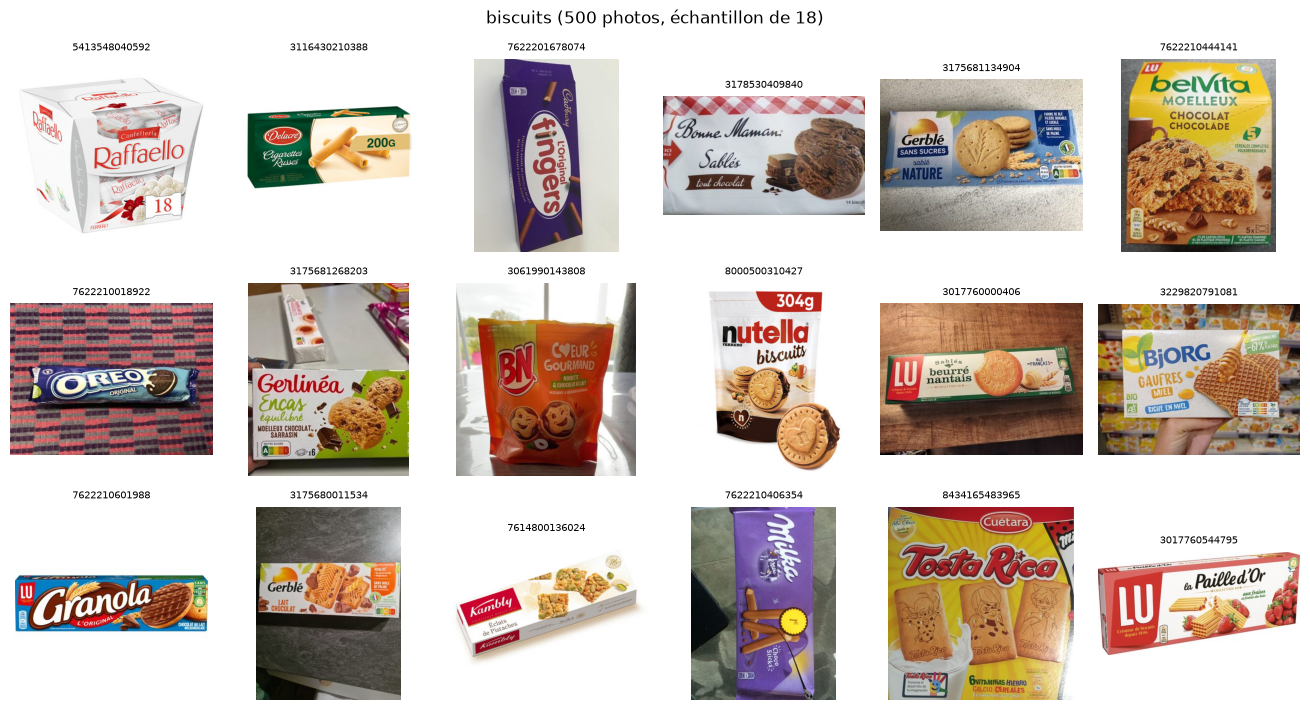

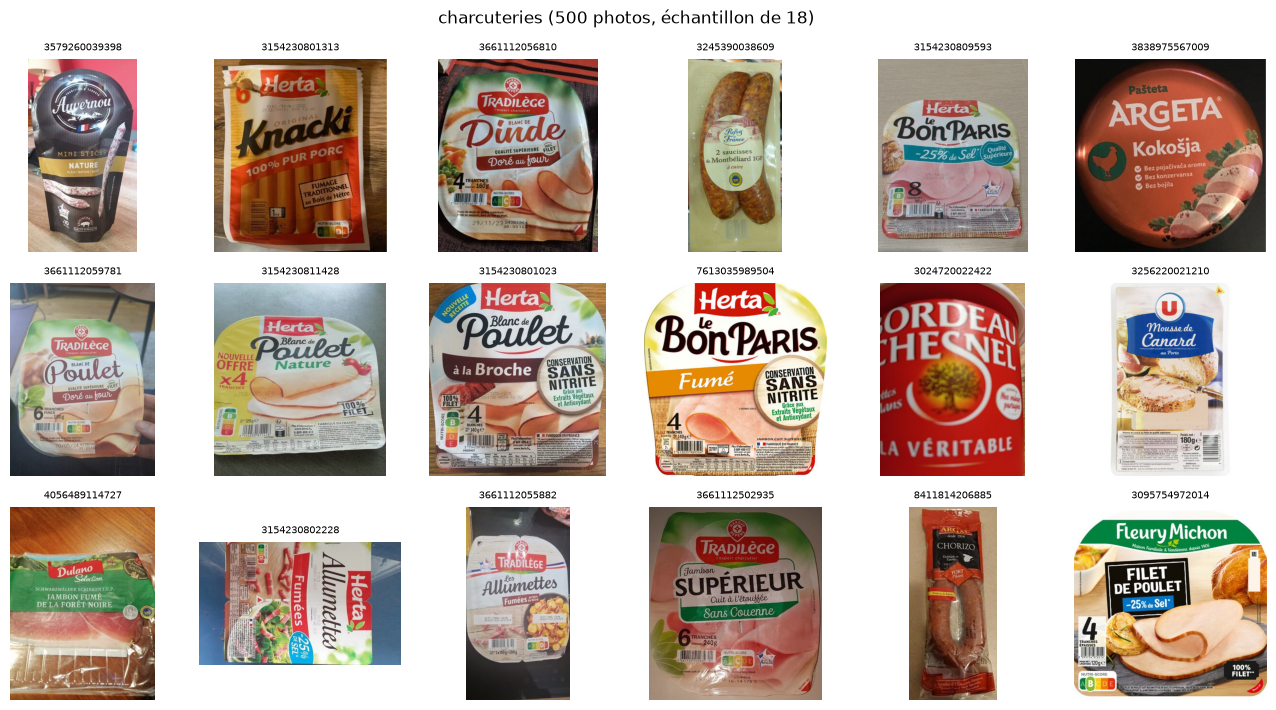

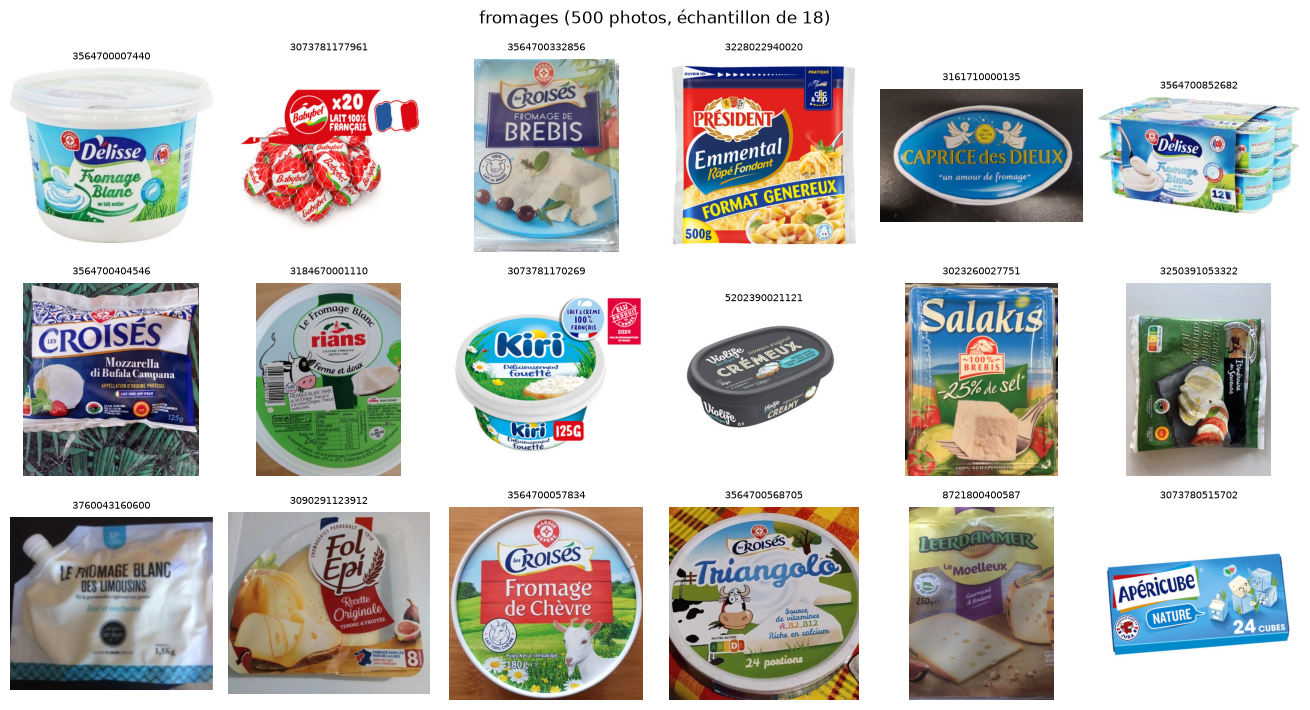

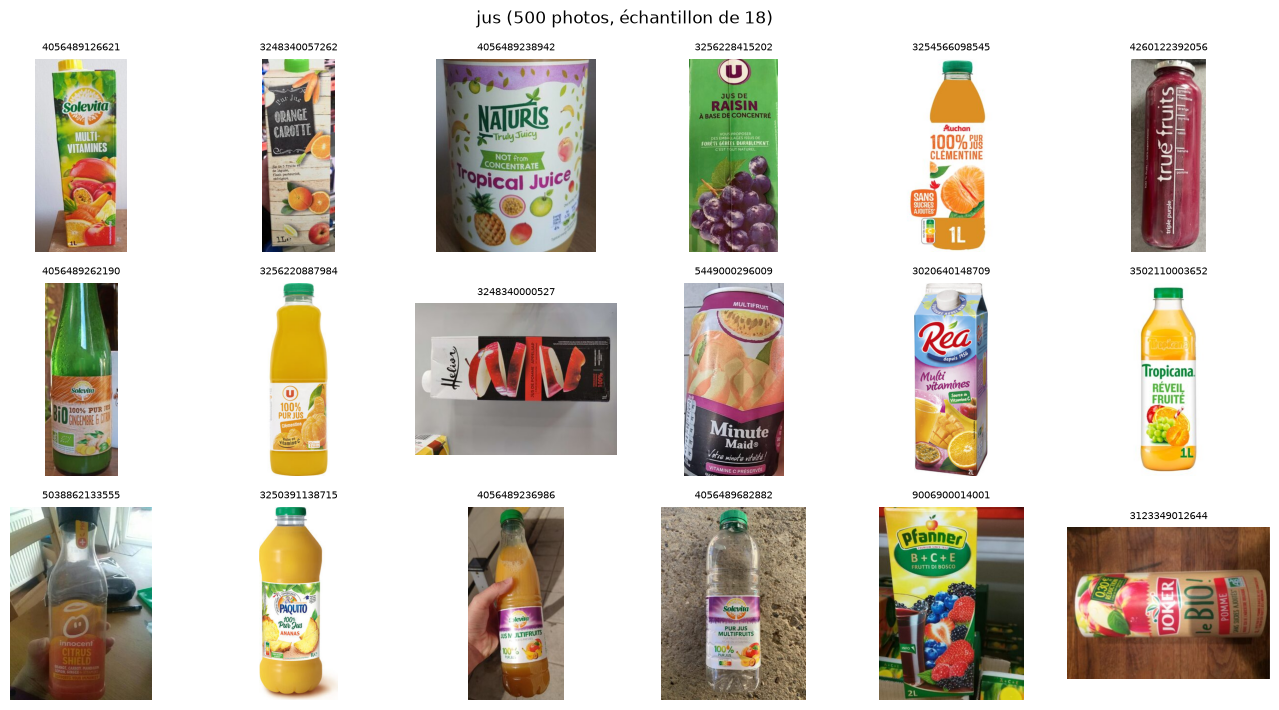

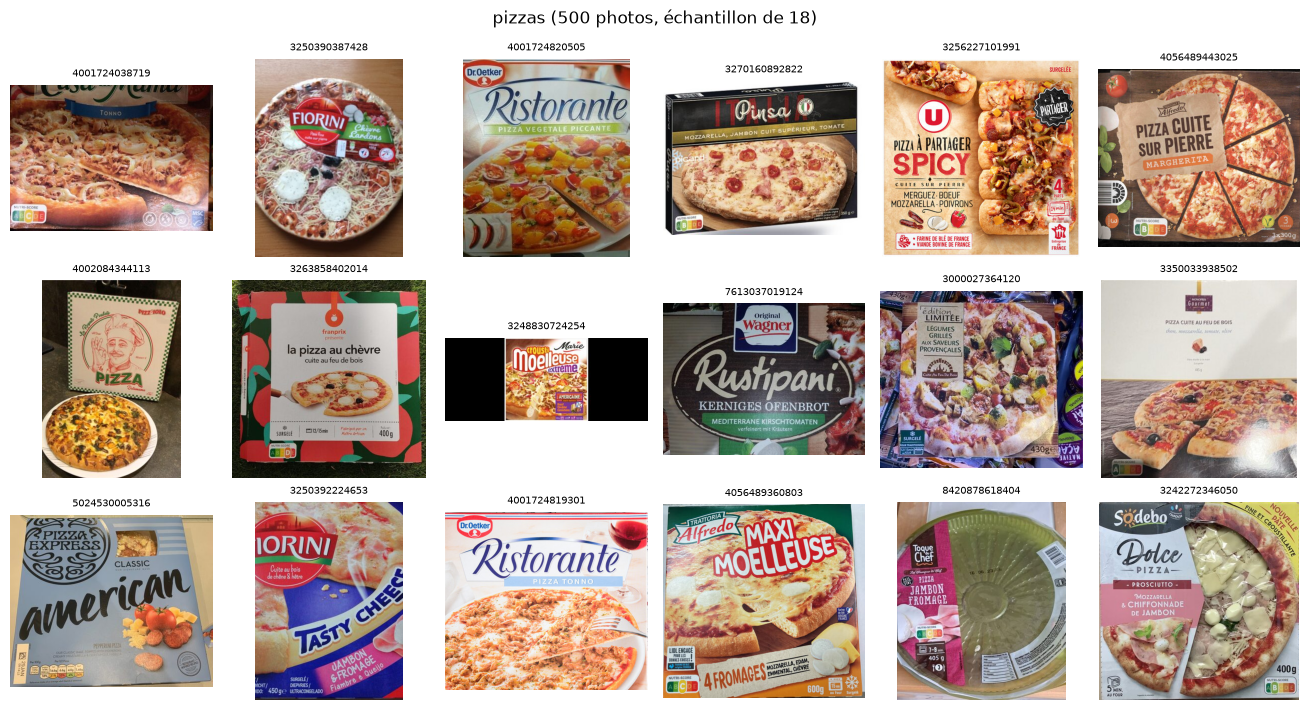

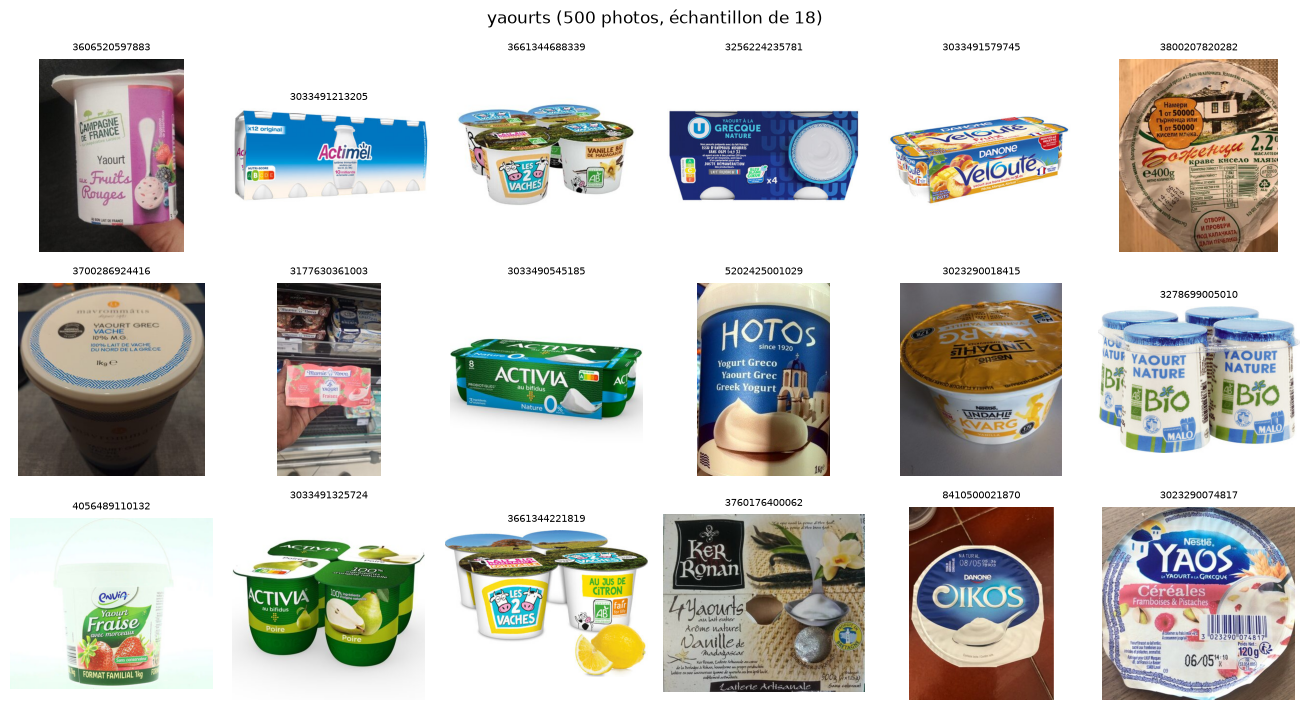

In [3]:
import math

import matplotlib.pyplot as plt

SEED = 42


def show_rayon(df: pd.DataFrame, rayon: str, n: int = 18, cols: int = 6) -> None:
    subset = df[(df["rayon"] == rayon) & df["ok"]]
    sample = subset.sample(n=min(n, len(subset)), random_state=SEED)
    rows = math.ceil(len(sample) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.4))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
        with Image.open(row["path"]) as img:
            ax.imshow(img)
        ax.set_title(row["code"], fontsize=7)
    fig.suptitle(f"{rayon} ({len(subset)} photos, échantillon de {len(sample)})", fontsize=12)
    plt.tight_layout()
    plt.show()


for rayon in sorted(df["rayon"].unique()):
    show_rayon(df, rayon)

# Observations

Sur les images ci-dessus (avec graine 42), elles sont de bonne qualité, au centre de l'image. Il y a très peu de mains sur les photos, et environ la moitié d'entre eux sont sur fond blanc. Le reste ont des fonds très variés (une table, un mur...). Les produits sont bien séparés et dans la bonne catégorie. Par contre, pour les charcuteries, les produits n'ont presque rien en commun (l'emballage du saucisson n'est pas pareil qu'un paquet de jambon). De plus, les fromages blancs ressemblent beaucoup aux yaourts. Dans l'ensemble, ce sont des données propres.

# CNN de zéro

In [4]:
df.head()

,path,rayon,code,width,height,ok
0,..\data\images\biscuits\0039047001442.jpg,biscuits,0039047001442,400,300,True
1,..\data\images\biscuits\0061232200293.jpg,biscuits,0061232200293,300,400,True
2,..\data\images\biscuits\0061232202556.jpg,biscuits,0061232202556,400,209,True
3,..\data\images\biscuits\0061232203072.jpg,biscuits,0061232203072,211,400,True
4,..\data\images\biscuits\0072417152924.jpg,biscuits,0072417152924,400,189,True


### Split train/test/val

Train : 72%, Test : 20 %, Validation : 8 %

In [5]:
from sklearn.model_selection import train_test_split

cible = "rayon"
y = df[cible]
X_raw = df.copy().drop(cible, axis=1)
rayons = sorted(y.unique())

X_train_raw, X_test, y_train_raw, y_test =train_test_split(X_raw, y, test_size=0.2, random_state=SEED, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_train_raw, y_train_raw, test_size=0.1, random_state=SEED, stratify=y_train_raw)

print("Dimensions train : ", X_train.shape, y_train.shape)
print("Dimensions val : ", X_val.shape, y_val.shape)
print("Dimensions test : ", X_test.shape, y_test.shape)

Dimensions train :  (2160, 5) (2160,)
Dimensions val :  (240, 5) (240,)
Dimensions test :  (600, 5) (600,)


In [6]:
import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

class_to_idx = {r: i for i, r in enumerate(rayons)}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def make_dataset(frame: pd.DataFrame, shuffle: bool) -> tf.data.Dataset:
    paths = frame["path"].astype(str).tolist()
    labels = frame["rayon"].map(class_to_idx).to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED)

    def load(path: tf.Tensor, label: tf.Tensor) -> tuple[tf.Tensor, tf.Tensor]:
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        img = tf.image.resize(img, IMG_SIZE)  # valeurs 0-255, pas de normalisation ici
        return img, tf.one_hot(label, len(rayons))

    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)


In [7]:
num_classes = len(rayons)

y_train_int = y_train.map(class_to_idx).to_numpy()
y_val_int = y_val.map(class_to_idx).to_numpy()
y_test_int = y_test.map(class_to_idx).to_numpy()

y_train_cat = tf.keras.utils.to_categorical(y_train_int, num_classes=num_classes)
y_val_cat = tf.keras.utils.to_categorical(y_val_int, num_classes=num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test_int, num_classes=num_classes)


train_dataset = make_dataset(X_train, shuffle=True)
val_dataset = make_dataset(X_val, shuffle=False)
test_dataset = make_dataset(X_test, shuffle=False)

KeyError: 'rayon'

In [ ]:
import numpy as np


def show_batch(ds: tf.data.Dataset, class_names: list[str], n: int = 12, cols: int = 6) -> None:
    images, labels = next(iter(ds.take(1)))  # un seul lot : (batch, 224, 224, 3)
    n = min(n, images.shape[0])
    rows = -(-n // cols)  # division entière par excès

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.4))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for i, ax in enumerate(np.atleast_1d(axes).ravel()[:n]):
        ax.imshow(images[i].numpy().astype("uint8"))
        ax.set_title(class_names[int(np.argmax(labels[i].numpy()))], fontsize=8)
    plt.tight_layout()
    plt.show()


show_batch(train_dataset, rayons)
show_batch(val_dataset, rayons)
show_batch(test_dataset, rayons)

In [ ]:
images, labels = next(iter(train_dataset))
print(images.shape, labels.shape)                         # (32, 224, 224, 3) (32, nb_rayons)
print(images.numpy().min(), images.numpy().max())          # attendu : ~0 et ~255
print(train_dataset.cardinality().numpy(), "lots")

### CNN

> Les images sont maintenant en 224*224, avec 3 comme c'est de la couleur. 32 est pour le batch

In [ ]:
from keras import models, layers


def build_cnn(num_classes=num_classes):
    model = models.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),

        # --- Bloc 1 : extraction de features simples ---
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 28×28 → 14×14
        layers.Dropout(0.25),

        # --- Bloc 2 : extraction de features complexes ---
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 14×14 → 7×7
        layers.Dropout(0.25),

        # --- Tête de classification ---
        layers.Flatten(),              # 7×7×64 = 3136 neurones
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name='CNN_FOOD')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
model = build_cnn()
model.summary()

In [ ]:
import os
from keras import callbacks

os.makedirs('checkpoints', exist_ok=True)

early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
)
model_ckpt = callbacks.ModelCheckpoint(
    filepath='checkpoints/cnn_img_best.keras',
    monitor='val_accuracy', save_best_only=True, verbose=0
)

history = model.fit(
    train_dataset,
    validation_data=(val_dataset),
    epochs=20,
    batch_size=128,
    verbose=1,
    callbacks=[early_stop, model_ckpt]
)
loss_fe, acc_fe = model.evaluate(train_dataset, verbose=0)
print(f"\n✓ Phase 1 terminée — Test Accuracy : {acc_fe:.4f} ({acc_fe*100:.2f}%)")

In [ ]:
from keras.src.metrics.metrics_utils import confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns

def plot_loss_acc(history, title=''):
    """Trace les courbes de loss et d'accuracy."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

    ax1.plot(history.history['loss'], label='Train', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Val', linewidth=2, linestyle='--')
    ax1.set_title(f'Loss {title}')
    ax1.set_xlabel('Époque')
    ax1.set_ylabel('Loss')
    ax1.legend();
    ax1.grid(alpha=0.3)

    ax2.plot(history.history['accuracy'], label='Train', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Val', linewidth=2, linestyle='--')
    ax2.set_title(f'Accuracy {title}')
    ax2.set_xlabel('Époque')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_loss_acc(history, '— CNN MNIST')
test_loss, test_acc = model.evaluate(test_dataset, y_test_cat, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}  ({test_acc * 100:.2f}%)")

y_pred = np.argmax(model.predict(test_dataset, verbose=0), axis=1)
class_names = [str(i) for i in range(10)]

print("\nClassification Report :")
print(classification_report(y_test_cat, y_pred, target_names=class_names))
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Matrice de Confusion — CNN sur MNIST", fontsize=13, fontweight='bold')
plt.xlabel("Classe Prédite", fontsize=11)
plt.ylabel("Classe Réelle", fontsize=11)
plt.tight_layout()
plt.show()